In [1]:
import pandas as pd

data_dir = "D:/movies_data/"


ratings = pd.read_csv(data_dir + "ratings.dat",
                      sep="::", engine="python",
                      names=["userId", "movieId", "rating", "timestamp"],encoding='Latin-1')


movies = pd.read_csv(data_dir + "movies.dat",
                     sep="::", engine="python",
                     names=["movieId", "title", "genres"],encoding='Latin-1')


users = pd.read_csv(data_dir + "users.dat",
                    sep="::", engine="python",
                    names=["userId", "gender", "age", "occupation", "zip"],encoding='Latin-1')


In [2]:
print(ratings.head())
print(ratings.shape)

   userId  movieId  rating  timestamp
0       1     1193       5  978300760
1       1      661       3  978302109
2       1      914       3  978301968
3       1     3408       4  978300275
4       1     2355       5  978824291
(1000209, 4)


In [5]:
#print(movies.head())
#print(movies.shape)

In [5]:
n_users = ratings["userId"].nunique()
n_movies = ratings["movieId"].nunique()
n_ratings = len(ratings)

print("Users:", n_users)
print("Movies:", n_movies)
print("Ratings:", n_ratings)


Users: 6040
Movies: 3706
Ratings: 1000209


In [9]:
# our dataset consist of 6040 unique users - we used groupby to capture how many movies are rated by each user

user_rating_counts = ratings.groupby("userId").size()

print(user_rating_counts.describe())



count    6040.000000
mean      165.597517
std       192.747029
min        20.000000
25%        44.000000
50%        96.000000
75%       208.000000
max      2314.000000
dtype: float64


In [11]:
print( user_rating_counts.sort_values(ascending=False).head(10))
# user with user ID 4169 rated 2314 movies



userId
4169    2314
1680    1850
4277    1743
1941    1595
1181    1521
889     1518
3618    1344
2063    1323
1150    1302
1015    1286
dtype: int64


In [13]:
# now we groupby movie ID - this tells us how many times a movie was rated by different users
movie_rating_counts = ratings.groupby("movieId").size()

print(movie_rating_counts.describe())


count    3706.000000
mean      269.889099
std       384.047838
min         1.000000
25%        33.000000
50%       123.500000
75%       350.000000
max      3428.000000
dtype: float64


In [17]:
print(movie_rating_counts.sort_values(ascending=False).head(10))

# as seen below movie with movieID 2858 is rated by 3428 users

movieId
2858    3428
260     2991
1196    2990
1210    2883
480     2672
2028    2653
589     2649
2571    2590
1270    2583
593     2578
dtype: int64


In [23]:
print(ratings["rating"].value_counts().sort_index())


rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64


In [25]:
print("Average rating:", ratings["rating"].mean())


Average rating: 3.581564453029317


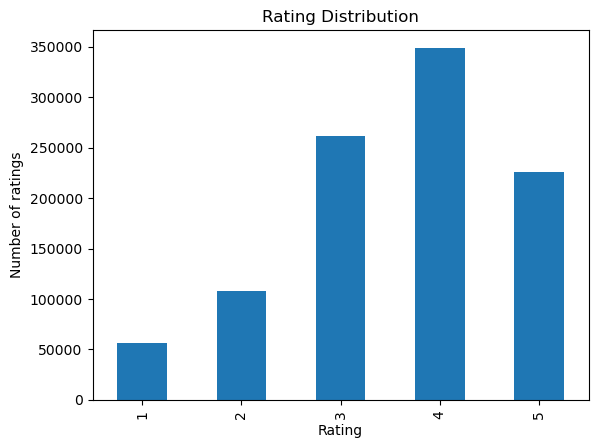

In [27]:
import matplotlib.pyplot as plt

ratings["rating"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.title("Rating Distribution")
plt.show()


In [29]:
user_movie_matrix = ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

print(user_movie_matrix.shape)


(6040, 3706)


In [25]:
print(user_movie_matrix.tail())


movieId  1     2     3     4     5     6     7     8     9     10    ...  \
userId                                                               ...   
6036      NaN   NaN   NaN   2.0   NaN   3.0   NaN   NaN   NaN   NaN  ...   
6037      NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
6038      NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
6039      NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
6040      3.0   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   

movieId  3943  3944  3945  3946  3947  3948  3949  3950  3951  3952  
userId                                                               
6036      NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
6037      NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
6038      NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
6039      NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
6040      NaN   NaN   NaN   NaN   NaN   NaN   N

In [33]:
from sklearn.model_selection import train_test_split

train_ratings, test_ratings = train_test_split(
    ratings,
    test_size=0.2,
    random_state=42
)

print("Train:", len(train_ratings))
print("Test:", len(test_ratings))


Train: 800167
Test: 200042


In [35]:
train_matrix = train_ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

print(train_matrix.shape)


(6040, 3683)


In [37]:
user_means = train_ratings.groupby("userId")["rating"].mean()

print(user_means.head())


userId
1    4.146341
2    3.733945
3    3.853659
4    4.210526
5    3.104575
Name: rating, dtype: float64


In [39]:
print(user_means.describe())


count    6040.000000
mean        3.703964
std         0.436801
min         1.021739
25%         3.443571
50%         3.739658
75%         4.000000
max         4.954545
Name: rating, dtype: float64


In [41]:
train_centered = train_ratings.copy()

train_centered["rating_centered"] = (
    train_centered["rating"]
    - train_centered["userId"].map(user_means)
)


In [43]:
print(train_centered)


        userId  movieId  rating  timestamp  rating_centered
416292    2507     3035       2  974076680        -1.944848
683230    4087     2840       4  965431652         1.183673
2434        19      457       3  978146863        -0.567164
688533    4118     2804       4  965804599        -0.011696
472584    2907      805       4  971838472         0.718659
...        ...      ...     ...        ...              ...
259178    1586     1077       5  974735719         0.585075
365838    2129     2700       5  974643199         1.758278
131932     854     3102       3  975355597        -0.070707
671155    4033     3479       5  965525805         1.247619
121958     786     1391       4  975429588         0.000000

[800167 rows x 5 columns]


In [47]:
centered_matrix = train_centered.pivot(
    index="userId",
    columns="movieId",
    values="rating_centered"
)

print(centered_matrix.shape)
print(centered_matrix.head())


(6040, 3683)
movieId      1     2     3     4     5     6     7     8     9     10    ...  \
userId                                                                   ...   
1        0.853659   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
2             NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
3             NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
4             NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
5             NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   

movieId  3943  3944  3945  3946  3947  3948  3949  3950  3951  3952  
userId                                                               
1         NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
2         NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
3         NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
4         NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
5     

In [49]:
centered_matrix_filled = centered_matrix.fillna(0)


In [51]:
print(centered_matrix_filled.shape)
print(centered_matrix_filled.iloc[:5, :10])


(6040, 3683)
movieId        1    2    3    4    5    6    7    8    9    10
userId                                                        
1        0.853659  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
2        0.000000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
3        0.000000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
4        0.000000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
5        0.000000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0


In [53]:
import numpy as np

U, S, Vt = np.linalg.svd(
    centered_matrix_filled,
    full_matrices=False
)

print("U shape:", U.shape)
print("S shape:", S.shape)
print("Vt shape:", Vt.shape)


U shape: (6040, 3683)
S shape: (3683,)
Vt shape: (3683, 3683)


In [48]:
print(S[:20])


[208.83605884 105.68299135  82.36216727  79.51255795  74.5471058
  70.84802801  64.5593516   61.93711374  59.66969417  59.41972568
  56.73727675  55.70999155  54.22923464  53.44765082  52.51267261
  51.55615878  51.33129992  50.27634972  49.7278648   49.08949753]


In [55]:
explained_variance = S**2 / np.sum(S**2)

print(explained_variance[:20])


[0.05170605 0.0132416  0.0080424  0.00749552 0.00658858 0.00595094
 0.00494138 0.00454812 0.00422122 0.00418593 0.00381652 0.00367957
 0.00348656 0.00338678 0.00326933 0.00315131 0.00312388 0.0029968
 0.00293177 0.00285698]


In [57]:
cumulative_variance = np.cumsum(explained_variance)

print(cumulative_variance[:20])


[0.05170605 0.06494765 0.07299005 0.08048558 0.08707416 0.0930251
 0.09796649 0.10251461 0.10673583 0.11092176 0.11473828 0.11841784
 0.1219044  0.12529119 0.12856052 0.13171183 0.13483571 0.13783251
 0.14076428 0.14362127]


In [59]:
print("First 20 singular values:")
print(S[:20])

print("\nFirst 20 explained variance:")
print(explained_variance[:20])

print("\nFirst 20 cumulative variance:")
print(cumulative_variance[:20])



First 20 singular values:
[208.83605884 105.68299135  82.36216727  79.51255795  74.5471058
  70.84802801  64.5593516   61.93711374  59.66969417  59.41972568
  56.73727675  55.70999155  54.22923464  53.44765082  52.51267261
  51.55615878  51.33129992  50.27634972  49.7278648   49.08949753]

First 20 explained variance:
[0.05170605 0.0132416  0.0080424  0.00749552 0.00658858 0.00595094
 0.00494138 0.00454812 0.00422122 0.00418593 0.00381652 0.00367957
 0.00348656 0.00338678 0.00326933 0.00315131 0.00312388 0.0029968
 0.00293177 0.00285698]

First 20 cumulative variance:
[0.05170605 0.06494765 0.07299005 0.08048558 0.08707416 0.0930251
 0.09796649 0.10251461 0.10673583 0.11092176 0.11473828 0.11841784
 0.1219044  0.12529119 0.12856052 0.13171183 0.13483571 0.13783251
 0.14076428 0.14362127]


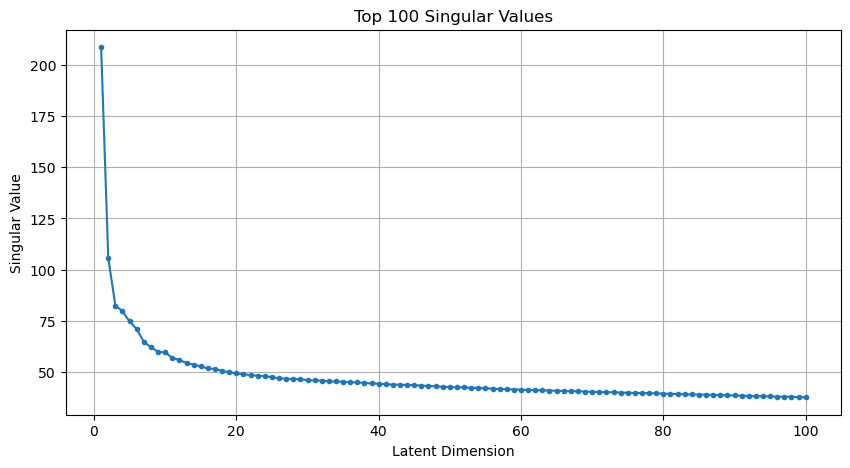

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 101),
    S[:100],
    marker="o",
    markersize=3
)

plt.xlabel("Latent Dimension")
plt.ylabel("Singular Value")
plt.title("Top 100 Singular Values")
plt.grid(True)

plt.show()


In [63]:
k = 20

U_k = U[:, :k]
S_k = S[:k]
Vt_k = Vt[:k, :]

print("U_k:", U_k.shape)
print("S_k:", S_k.shape)
print("Vt_k:", Vt_k.shape)


U_k: (6040, 20)
S_k: (20,)
Vt_k: (20, 3683)


In [65]:
S_k_matrix = np.diag(S_k)

print(S_k_matrix.shape)


(20, 20)


In [67]:
R_approx = U_k @ S_k_matrix @ Vt_k

print(R_approx.shape)


(6040, 3683)


In [69]:
user_idx = 0

print("Original centered ratings:")
print(centered_matrix_filled.iloc[user_idx, :20].values)

print("\nReconstructed ratings:")
print(R_approx[user_idx, :20])


Original centered ratings:
[0.85365854 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.        ]

Reconstructed ratings:
[ 0.12906153  0.01208061  0.01908313  0.00919146  0.00770139 -0.01232176
  0.00539996 -0.00068983 -0.00647665 -0.01360912  0.01254516  0.00859012
 -0.0002997   0.0077369  -0.00964406  0.00838591  0.01297839 -0.01016335
 -0.00360919 -0.01182623]


In [105]:
k = 20

U_k = U[:, :k]
S_k = S[:k]
Vt_k = Vt[:k, :]

print(U_k.shape)
print(S_k.shape)
print(Vt_k.shape)


(6040, 20)
(20,)
(20, 3683)


In [107]:
P = U_k * S_k


In [109]:
P.shape

(6040, 20)

In [111]:
P[0]

array([-0.16749713, -0.2640693 ,  0.26134871, -0.35972938,  0.15874495,
        0.30921919, -0.37253122, -0.19855909, -0.12265354, -0.13740361,
       -0.087228  ,  0.070672  , -0.0414683 ,  0.26059186, -0.40698861,
        0.23242031,  0.01189735,  0.27226083, -0.337937  , -0.19047247])

In [71]:
Q = Vt_k.T

print(Q.shape)


(3683, 20)


In [73]:
S_matrix = np.diag(S_k)
P = U_k @ S_matrix


In [75]:
print("User 1 latent vector:")
print(P[0])

print("Movie 1 latent vector:")
print(Q[0])


User 1 latent vector:
[-0.16749713 -0.2640693   0.26134871 -0.35972938  0.15874495  0.30921919
 -0.37253122 -0.19855909 -0.12265354 -0.13740361 -0.087228    0.070672
 -0.0414683   0.26059186 -0.40698861  0.23242031  0.01189735  0.27226083
 -0.337937   -0.19047247]
Movie 1 latent vector:
[-6.95178541e-02 -5.72253023e-02  3.44275813e-02 -3.08330169e-02
  4.22243628e-02 -1.07995099e-01  2.22017505e-02 -9.02865951e-02
  3.88086003e-02  3.78449717e-02 -4.43867857e-02  1.52050916e-02
 -1.66690120e-05  1.20374102e-01 -7.41619943e-02  1.97815697e-02
 -1.39629367e-03  1.55136320e-01 -4.08819142e-03  2.88069793e-02]


In [77]:
user_idx = 0
movie_idx = 0

centered_prediction = P[user_idx] @ Q[movie_idx]

print("Predicted centered rating:", centered_prediction)


Predicted centered rating: 0.12906153023451136


In [79]:
print("From P @ Q.T:", centered_prediction)
print("From R_approx:", R_approx[user_idx, movie_idx])


From P @ Q.T: 0.12906153023451136
From R_approx: 0.12906153023451136


In [81]:
user_id = train_matrix.index[user_idx]
print("User ID:", user_id)


User ID: 1


In [83]:
user_mean = user_means.loc[user_id]
print("User mean:", user_mean)


User mean: 4.146341463414634


In [85]:
predicted_rating = user_mean + centered_prediction
print("Predicted rating:", predicted_rating)


Predicted rating: 4.275402993649146


In [87]:
user_idx = 1

predicted_centered = P[user_idx] @ Q.T

predicted_ratings = (
    user_means.loc[train_matrix.index[user_idx]]
    + predicted_centered
)

print(predicted_ratings.shape)


(3683,)


In [89]:
predicted_ratings

array([3.87572249, 3.69619549, 3.72951151, ..., 3.74398402, 3.73518783,
       3.74842178])

In [91]:
user_id = train_matrix.index[user_idx]

rated_movies = train_matrix.loc[user_id].notna()

predicted_ratings[rated_movies.values] = -np.inf
print(rated_movies)

movieId
1       False
2       False
3       False
4       False
5       False
        ...  
3948    False
3949    False
3950    False
3951    False
3952    False
Name: 2, Length: 3683, dtype: bool


In [93]:
top_indices = np.argsort(predicted_ratings)[::-1][:10]

print(top_indices)
print(predicted_ratings[top_indices])


[ 511 2543 1019 1556 1282 1771  143  796 2119  252]
[4.58439338 4.18371702 4.17375674 4.05145421 4.03374463 4.0284593
 4.02132044 3.99248393 3.98698117 3.96305456]


In [95]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [99]:
movie_ids = train_matrix.columns

recommended_movie_ids = movie_ids[top_indices]

print(recommended_movie_ids)


Index([527, 2762, 1097, 1704, 1387, 1961, 150, 858, 2324, 260], dtype='int64', name='movieId')


In [101]:
recommendations = movies[
    movies["movieId"].isin(recommended_movie_ids)
]

print(recommendations)


      movieId                                       title  \
148       150                            Apollo 13 (1995)   
257       260   Star Wars: Episode IV - A New Hope (1977)   
523       527                     Schindler's List (1993)   
847       858                       Godfather, The (1972)   
1081     1097           E.T. the Extra-Terrestrial (1982)   
1366     1387                                 Jaws (1975)   
1656     1704                    Good Will Hunting (1997)   
1892     1961                             Rain Man (1988)   
2255     2324  Life Is Beautiful (La Vita è bella) (1997)   
2693     2762                     Sixth Sense, The (1999)   

                               genres  
148                             Drama  
257   Action|Adventure|Fantasy|Sci-Fi  
523                         Drama|War  
847                Action|Crime|Drama  
1081  Children's|Drama|Fantasy|Sci-Fi  
1366                    Action|Horror  
1656                            Drama  
1892    

In [103]:
recommendations

,movieId,title,genres
148,150,Apollo 13 (1995),Drama
257,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi
523,527,Schindler's List (1993),Drama|War
847,858,"Godfather, The (1972)",Action|Crime|Drama
1081,1097,E.T. the Extra-Terrestrial (1982),Children's|Drama|Fantasy|Sci-Fi
1366,1387,Jaws (1975),Action|Horror
1656,1704,Good Will Hunting (1997),Drama
1892,1961,Rain Man (1988),Drama
2255,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama
2693,2762,"Sixth Sense, The (1999)",Thriller
